**JPEG2000 Encoder**

A small, lightweight JP2 encoder that mirrors the structure of `JPEG.ipynb`.
Uses `glymur` to write JP2 files. If `glymur` is not installed the notebook will attempt to install it (note: `glymur` needs OpenJPEG installed on the system).


[1] Processing: C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Gradient_sq_gray.png -> stem=Gradient_sq_gray


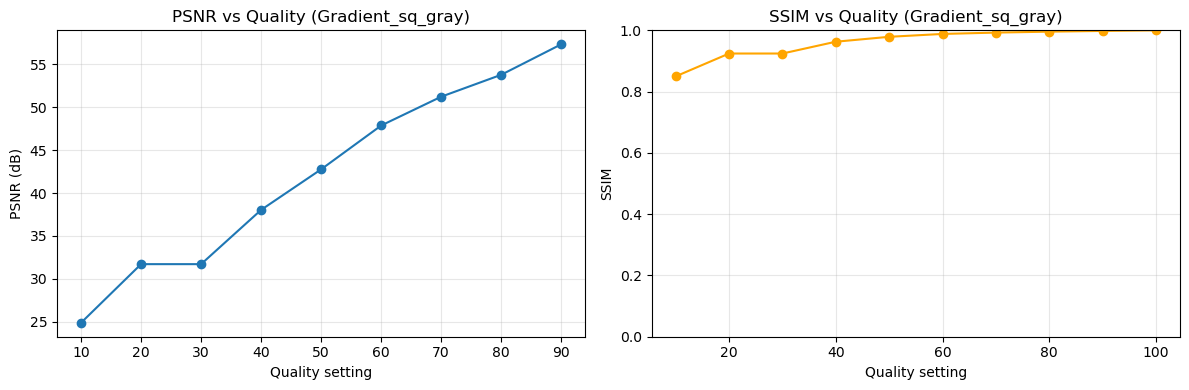


Saved highest quality JP2 (lossless): Gradient_sq_gray_Q100.jp2 (675.1 KB)
At Q=100: PSNR=inf dB, SSIM=1.0000
At quality=50 (display only): PSNR=42.77 dB, SSIM=0.9789
At quality=50 (display only): PSNR=42.77 dB, SSIM=0.9789


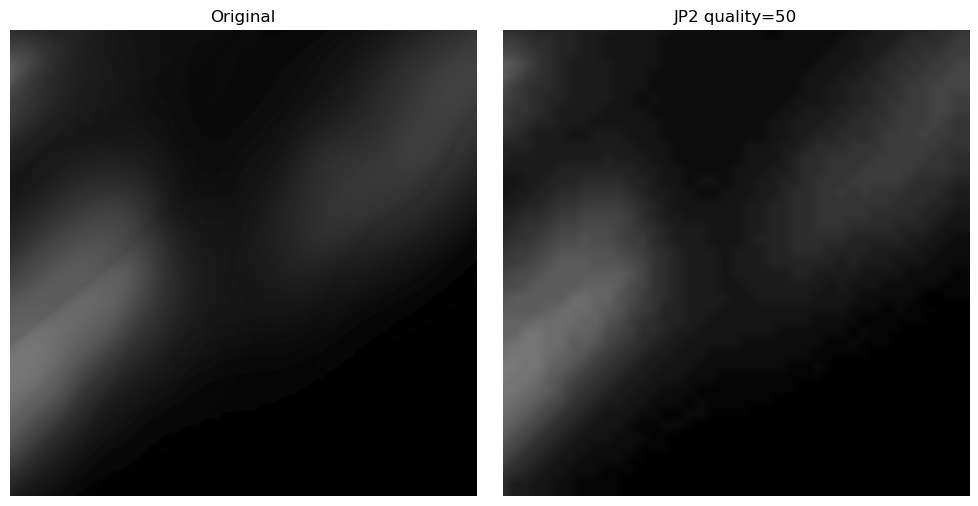


[2] Processing: C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Grass_sq_gray.png -> stem=Grass_sq_gray


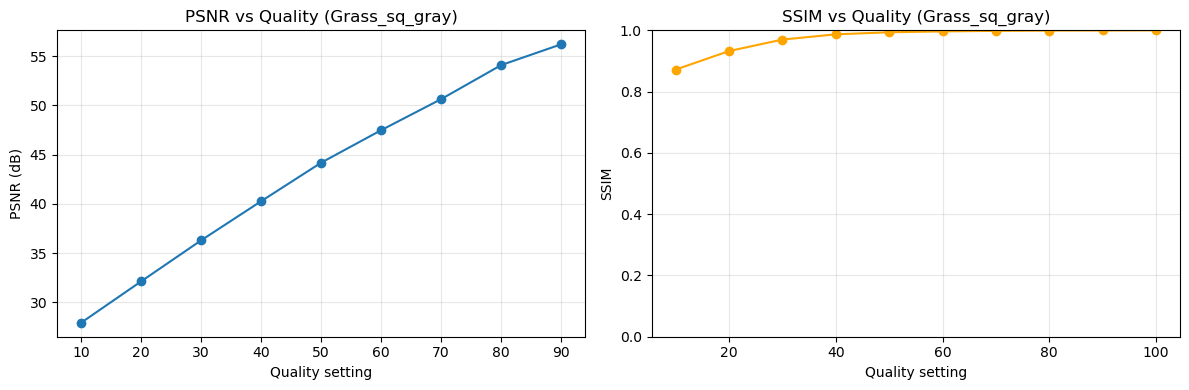


Saved highest quality JP2 (lossless): Grass_sq_gray_Q100.jp2 (906.8 KB)
At Q=100: PSNR=inf dB, SSIM=1.0000
At quality=50 (display only): PSNR=44.18 dB, SSIM=0.9936
At quality=50 (display only): PSNR=44.18 dB, SSIM=0.9936


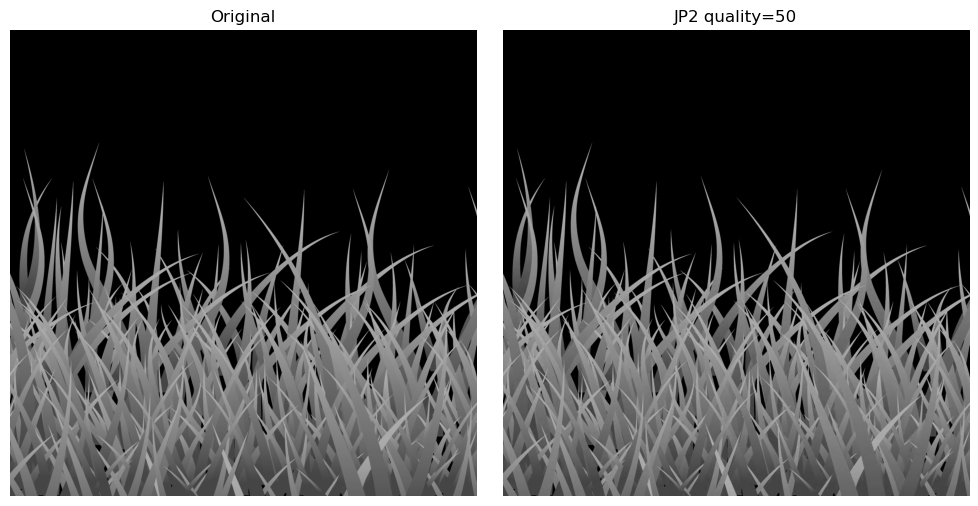


[3] Processing: C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Mixed_sq_gray.png -> stem=Mixed_sq_gray


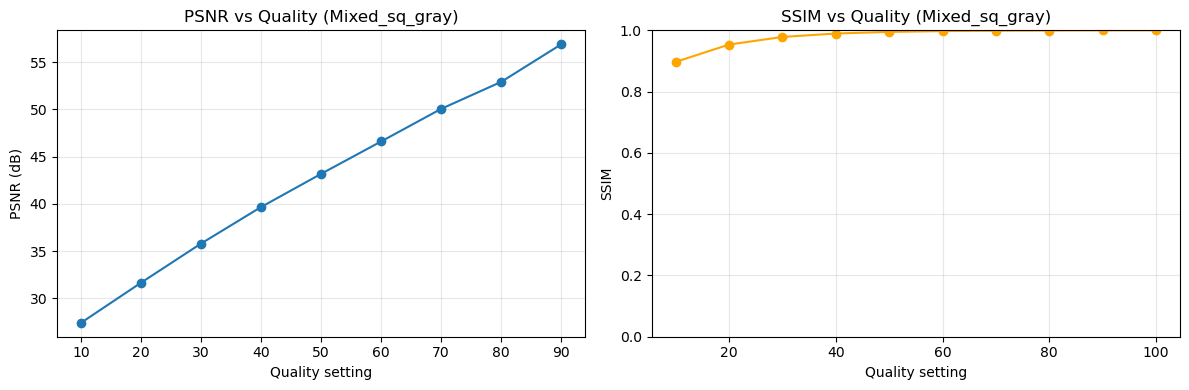


Saved highest quality JP2 (lossless): Mixed_sq_gray_Q100.jp2 (2.04 MB)
At Q=100: PSNR=inf dB, SSIM=1.0000
At quality=50 (display only): PSNR=43.18 dB, SSIM=0.9949
At quality=50 (display only): PSNR=43.18 dB, SSIM=0.9949


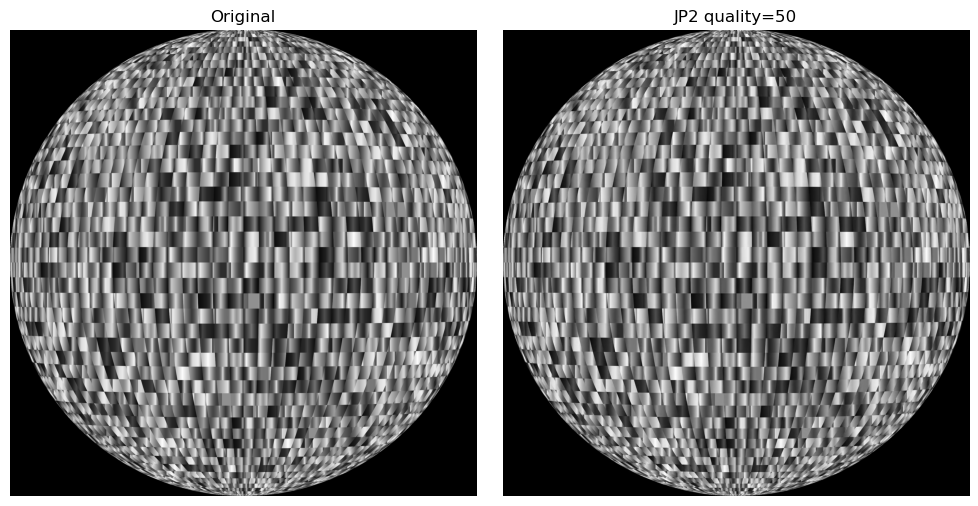


[4] Processing: C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Nature_sq_gray.png -> stem=Nature_sq_gray


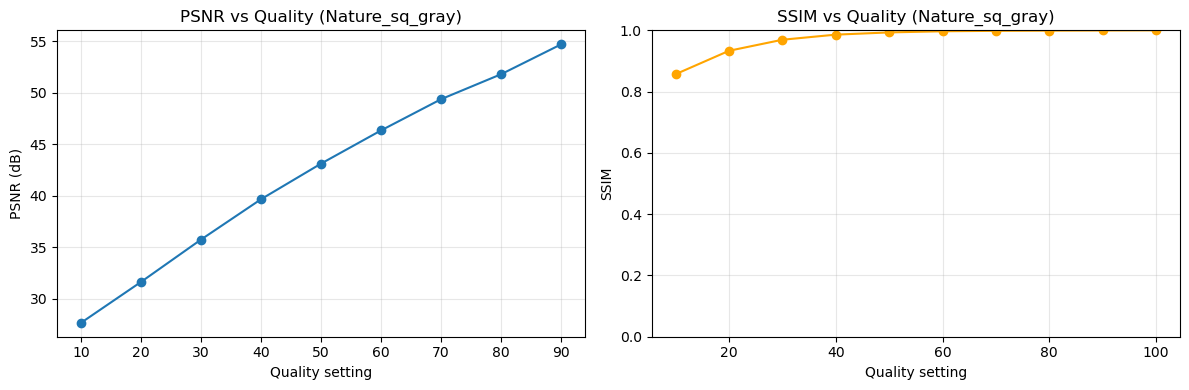


Saved highest quality JP2 (lossless): Nature_sq_gray_Q100.jp2 (2.25 MB)
At Q=100: PSNR=inf dB, SSIM=1.0000
At quality=50 (display only): PSNR=43.13 dB, SSIM=0.9932
At quality=50 (display only): PSNR=43.13 dB, SSIM=0.9932


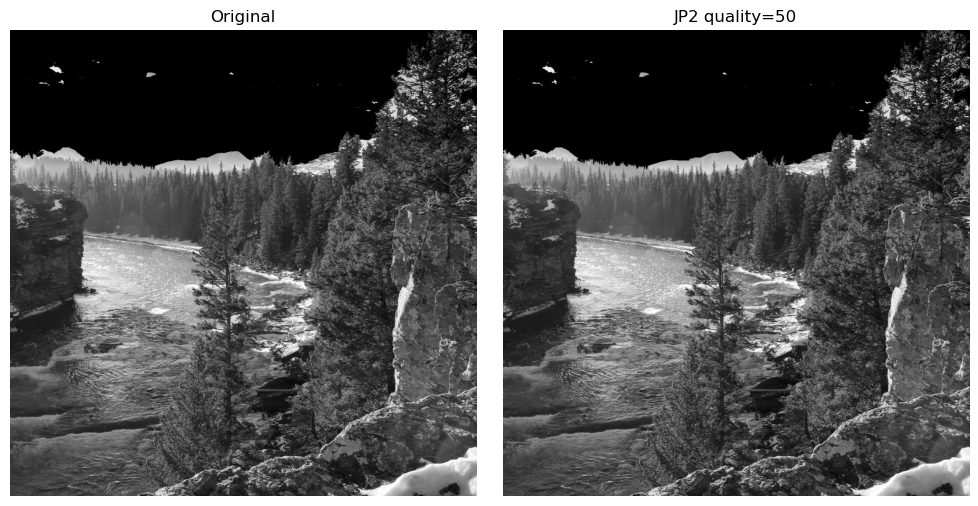


[5] Processing: C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\SharpEdges_sq_gray.png -> stem=SharpEdges_sq_gray


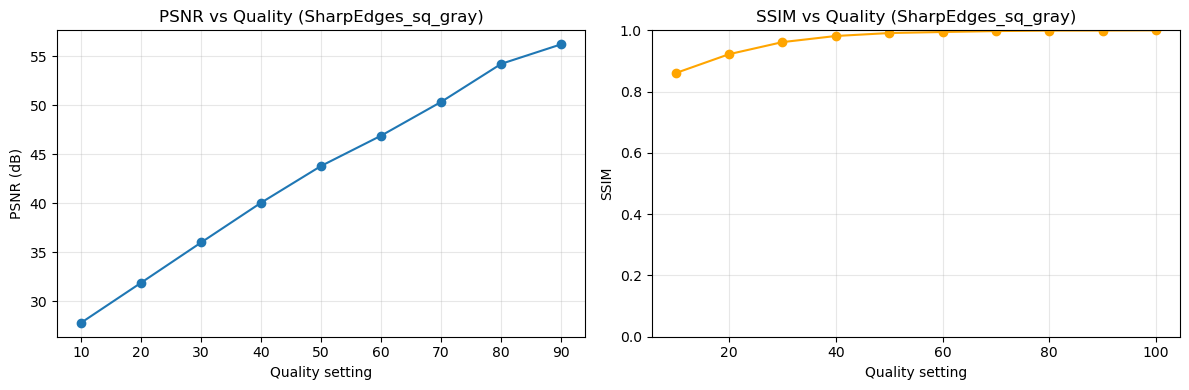


Saved highest quality JP2 (lossless): SharpEdges_sq_gray_Q100.jp2 (457.8 KB)
At Q=100: PSNR=inf dB, SSIM=1.0000
At quality=50 (display only): PSNR=43.80 dB, SSIM=0.9912
At quality=50 (display only): PSNR=43.80 dB, SSIM=0.9912


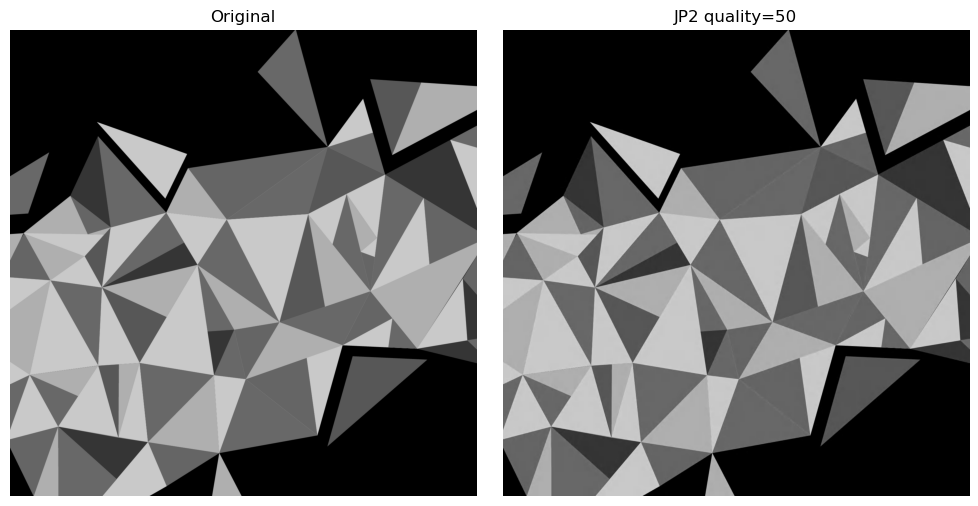


All done.


In [1]:
# Lightweight JPEG2000 encoder example
# - Uses PIL/Pillow with JPEG2000 support
# - defines PSNR/SSIM helpers (same as JPEG.ipynb)
# - encodes a set of images to JP2 and computes metrics and plots

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import io

# --- User: replace these with your image file paths (up to 5) ---
image_paths = [
    r"C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Gradient_sq_gray.png",
    r"C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Grass_sq_gray.png",
    r"C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Mixed_sq_gray.png",
    r"C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Nature_sq_gray.png",
    r"C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\SharpEdges_sq_gray.png"
]

# --- Helpers: PSNR / SSIM (same algorithm as in JPEG.ipynb) ---
import math

def psnr(img1, img2, data_range=255.0):
    x = img1.astype(np.float64)
    y = img2.astype(np.float64)
    mse = np.mean((x - y) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * np.log10(data_range) - 10 * np.log10(mse)


def _box_filter_same(img, w):
    if img.ndim == 2:
        img = img[..., None]
        squeeze = True
    else:
        squeeze = False
    pad = w // 2
    img_p = np.pad(img, ((pad, pad), (pad, pad), (0, 0)), mode='reflect')
    tmp = np.cumsum(img_p, axis=0)
    tmp = tmp[w:, :, :] - tmp[:-w, :, :]
    tmp2 = np.cumsum(tmp, axis=1)
    res = tmp2[:, w:, :] - tmp2[:, :-w, :]
    res = res / (w * w)
    if squeeze:
        return res[..., 0]
    return res


def ssim(img1, img2, data_range=255.0, win_size=11, K1=0.01, K2=0.03):
    x = img1.astype(np.float64)
    y = img2.astype(np.float64)
    C1 = (K1 * data_range) ** 2
    C2 = (K2 * data_range) ** 2
    mu_x = _box_filter_same(x, win_size)
    mu_y = _box_filter_same(y, win_size)
    sigma_x2 = _box_filter_same(x * x, win_size) - mu_x * mu_x
    sigma_y2 = _box_filter_same(y * y, win_size) - mu_y * mu_y
    sigma_xy = _box_filter_same(x * y, win_size) - mu_x * mu_y
    num = (2 * mu_x * mu_y + C1) * (2 * sigma_xy + C2)
    den = (mu_x * mu_x + mu_y * mu_y + C1) * (sigma_x2 + sigma_y2 + C2)
    ssim_map = num / (den + 1e-12)
    return float(np.mean(ssim_map))

# --- Processing parameters ---
# Quality levels using PSNR targets (dB) - higher = better quality
quality_levels = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]  # user-friendly quality scale
psnr_targets = [28, 32, 36, 40, 44, 48, 52, 56, 60, 70]     # corresponding PSNR targets in dB (100 gets lossless)
chosen_quality_idx = 4  # index for display (quality 50)

# utility for human file sizes
def fmt_bytes(b):
    if b is None:
        return 'N/A'
    if b < 1024:
        return f"{b} B"
    kb = b / 1024.0
    if kb < 1024:
        return f"{kb:.1f} KB"
    mb = kb / 1024.0
    return f"{mb:.2f} MB"

# --- Run over image slots ---
for idx, p in enumerate(image_paths):
    if not p:
        continue
    path = Path(p)
    if not path.exists():
        print(f"[{idx+1}] Path not found: {p}")
        continue

    stem = path.stem

    print('\n' + '=' * 60)
    print(f"[{idx+1}] Processing: {path} -> stem={stem}")

    pil = Image.open(path).convert('RGB')
    orig = np.array(pil, dtype=np.uint8)

    per_cr_metrics = []
    rec_cache = {}

    # Sweep quality levels and compute metrics (in memory only)
    for i, quality in enumerate(quality_levels):
        psnr_target = psnr_targets[i]
        buf = io.BytesIO()
        try:
            # Save to JPEG2000 in-memory with appropriate quality control
            pil_img = Image.fromarray(orig)
            if quality == 100:
                # Use lossless mode for highest quality
                pil_img.save(buf, 'JPEG2000', irreversible=False)
            else:
                # Use dB mode for other qualities
                pil_img.save(buf, 'JPEG2000', quality_mode='dB', quality_layers=[psnr_target])
            buf.seek(0)
        except Exception as e:
            print(f'  Failed to encode quality={quality}: {e}')
            continue
        
        try:
            # Read back using PIL
            rec_pil = Image.open(buf)
            rec = np.array(rec_pil, dtype=np.uint8)
        except Exception as e:
            print(f'  Failed to decode quality={quality}: {e}')
            continue

        psnr_val = psnr(orig, rec)
        ssim_val = ssim(orig, rec)
        rec_cache[quality] = rec

        per_cr_metrics.append({
            'quality': quality,
            'psnr': psnr_val,
            'ssim': ssim_val
        })

    if not per_cr_metrics:
        print('No JP2 outputs were generated for this image; skipping plots and tables.')
        continue

    q_available = [m['quality'] for m in per_cr_metrics]
    psnrs = [m['psnr'] for m in per_cr_metrics]
    ssims = [m['ssim'] for m in per_cr_metrics]

    # Plot PSNR/SSIM curves
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(q_available, psnrs, marker='o')
    ax[0].set_title(f'PSNR vs Quality ({stem})')
    ax[0].set_xlabel('Quality setting')
    ax[0].set_ylabel('PSNR (dB)')
    ax[0].grid(True, alpha=0.3)

    ax[1].plot(q_available, ssims, marker='o', color='orange')
    ax[1].set_title(f'SSIM vs Quality ({stem})')
    ax[1].set_xlabel('Quality setting')
    ax[1].set_ylabel('SSIM')
    ax[1].set_ylim(0, 1.0)
    ax[1].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Save highest quality image to disk
    out_jp2 = Path(f"{stem}_Q100.jp2")
    try:
        # Save with lossless compression
        pil.save(str(out_jp2), 'JPEG2000', irreversible=False)
        
        size_jp2 = out_jp2.stat().st_size
        
        # Get metrics from already computed Q100
        psnr_100 = next((m['psnr'] for m in per_cr_metrics if m['quality'] == 100), None)
        ssim_100 = next((m['ssim'] for m in per_cr_metrics if m['quality'] == 100), None)
        
        print(f"\nSaved highest quality JP2 (lossless): {out_jp2} ({fmt_bytes(size_jp2)})")
        if psnr_100 and ssim_100:
            print(f"At Q=100: PSNR={psnr_100:.2f} dB, SSIM={ssim_100:.4f}")
    except Exception as e:
        print(f"Failed to save highest quality JP2: {e}")

    # Pick quality for display
    if len(per_cr_metrics) > chosen_quality_idx:
        best_metric = per_cr_metrics[chosen_quality_idx]
        sel_q = best_metric['quality']
    else:
        best_metric = max(per_cr_metrics, key=lambda m: m['ssim'])
        sel_q = best_metric['quality']

    rec_sel = rec_cache[sel_q]

    psnr_chosen = psnr(orig, rec_sel)
    ssim_chosen = ssim(orig, rec_sel)
    
    print(f"At quality={sel_q} (display only): PSNR={psnr_chosen:.2f} dB, SSIM={ssim_chosen:.4f}")

    # Display side-by-side
    fig2, ax2 = plt.subplots(1, 2, figsize=(10, 5))
    ax2[0].imshow(orig)
    ax2[0].set_title('Original')
    ax2[0].axis('off')
    ax2[1].imshow(rec_sel)
    ax2[1].set_title(f'JP2 quality={sel_q}')
    ax2[1].axis('off')
    plt.tight_layout()
    plt.show()

print('\nAll done.')


**Interpreting the curves**

Higher quality settings produce better reconstructions with higher PSNR and SSIM values. Unlike compression ratios, quality increases from left to right on the plots. The encoder uses PSNR targets scaled appropriately for JPEG2000's wavelet-based compression.

In [2]:
# --- JPEG2000 encoding time vs quality with PSNR/SSIM ---
import time
import pandas as pd

jp2_stats = {}

for idx, p in enumerate(image_paths):
    if not p:
        continue
    path = Path(p)
    if not path.exists():
        print(f"[{idx+1}] Path not found: {p}")
        continue

    stem = path.stem
    pil = Image.open(path).convert('RGB')
    orig = np.array(pil, dtype=np.uint8)

    records = []
    for quality, psnr_target in zip(quality_levels, psnr_targets):
        buf = io.BytesIO()
        start = time.perf_counter()
        try:
            if quality == 100:
                pil.save(buf, 'JPEG2000', irreversible=False)
            else:
                pil.save(buf, 'JPEG2000', quality_mode='dB', quality_layers=[psnr_target])
        except Exception as exc:
            print(f"[{stem}] Failed to encode Q={quality}: {exc}")
            continue
        elapsed = time.perf_counter() - start
        buf.seek(0)

        try:
            rec = np.array(Image.open(buf).convert('RGB'), dtype=np.uint8)
        except Exception as exc:
            print(f"[{stem}] Failed to decode Q={quality}: {exc}")
            continue

        psnr_val = psnr(orig, rec)
        ssim_val = ssim(orig, rec)

        records.append({
            'Quality': quality,
            'Encode Time (s)': elapsed,
            'PSNR (dB)': psnr_val,
            'SSIM': ssim_val
        })

    if not records:
        continue

    df = pd.DataFrame(records)
    jp2_stats[stem] = df
    display(
        df.style
          .format({'Encode Time (s)': '{:.4f}', 'PSNR (dB)': '{:.2f}', 'SSIM': '{:.4f}'})
          .set_caption(f'JPEG2000 encode metrics vs quality ({stem})')
    )

,Quality,Encode Time (s),PSNR (dB),SSIM
0,10,0.1562,24.88,0.8498
1,20,0.2053,31.72,0.9243
2,30,0.1754,31.72,0.9243
3,40,0.1734,38.04,0.9629
4,50,0.1517,42.77,0.9789
5,60,0.1634,47.87,0.9882
6,70,0.1640,51.23,0.9926
7,80,0.1701,53.79,0.9957
8,90,0.1558,57.34,0.9981
9,100,0.6900,inf,1.0000


,Quality,Encode Time (s),PSNR (dB),SSIM
0,10,0.2370,27.92,0.8720
1,20,0.2609,32.12,0.9324
2,30,0.2379,36.29,0.9699
3,40,0.2897,40.26,0.9870
4,50,0.2676,44.18,0.9936
5,60,0.2624,47.48,0.9965
6,70,0.2707,50.63,0.9982
7,80,0.2532,54.08,0.9992
8,90,0.3001,56.19,0.9995
9,100,0.2436,inf,1.0000


,Quality,Encode Time (s),PSNR (dB),SSIM
0,10,0.7091,27.39,0.8970
1,20,0.7427,31.64,0.9536
2,30,0.7431,35.79,0.9784
3,40,0.7199,39.66,0.9896
4,50,0.7738,43.18,0.9949
5,60,0.6551,46.62,0.9975
6,70,1.2760,50.07,0.9988
7,80,0.7436,52.93,0.9994
8,90,0.8798,56.91,0.9998
9,100,0.8401,inf,1.0000


,Quality,Encode Time (s),PSNR (dB),SSIM
0,10,0.6394,27.67,0.8571
1,20,0.5352,31.65,0.9333
2,30,0.5189,35.76,0.9693
3,40,0.4885,39.68,0.9859
4,50,0.4725,43.13,0.9932
5,60,0.5199,46.36,0.9969
6,70,0.4648,49.39,0.9984
7,80,0.6097,51.81,0.9990
8,90,0.4951,54.71,0.9995
9,100,0.4379,inf,1.0000


,Quality,Encode Time (s),PSNR (dB),SSIM
0,10,0.6804,27.80,0.8605
1,20,0.2366,31.88,0.9222
2,30,0.2516,35.99,0.9615
3,40,0.2158,40.05,0.9815
4,50,0.2088,43.80,0.9912
5,60,0.2719,46.89,0.9945
6,70,0.2093,50.34,0.9976
7,80,0.2259,54.22,0.9991
8,90,0.2104,56.21,0.9993
9,100,0.2489,inf,1.0000
